# Assignment 2 — Interpolation-Based Super-Resolution
Four 512×512 grayscale images → Gaussian-pyramid downsampling to 256/128/64 → interpolation back to 512 with orders 0–5 (+ cubic convolution, Lanczos) → PSNR, SSIM, runtime.

All operators live in `code/a2_ops.py`. Metrics and timing live in `code/a2_eval.py`.

In [1]:
import sys, time
sys.path.insert(0, 'code')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import a2_ops as ops, a2_eval as ev, run_assignment as ra
pd.set_option('display.precision', 3)
images = ra.load()
list(images)

['4.2.03.tiff', '7.1.02.tiff', '7.1.03.tiff', '4.2.06.tiff']

## 1. Prelude: nearest neighbour on the PDF example, plus a hand-checkable bilinear value

In [2]:
toy = np.array([[40., 120.], [180., 220.]])
print('nearest 2x:\n', ops.upsample(toy, 2, 'nearest', 'centered'))
bl = ops.upsample(toy, 2, 'bilinear', 'centered')
hand = .75*.75*40 + .75*.25*120 + .25*.75*180 + .25*.25*220   # output (1,1) -> input (0.25, 0.25)
print('bilinear 2x:\n', bl.round(2)); print('hand value at (1,1):', hand)

nearest 2x:
 [[ 40.  40. 120. 120.]
 [ 40.  40. 120. 120.]
 [180. 180. 220. 220.]
 [180. 180. 220. 220.]]
bilinear 2x:
 [[ 40.   60.  100.  120. ]
 [ 75.   92.5 127.5 145. ]
 [145.  157.5 182.5 195. ]
 [180.  190.  210.  220. ]]
hand value at (1,1): 92.5


## 2. Coordinate convention check
LR pixel *i* covers HR block [s·i, s·i+s), so output *u* maps to x=(u+0.5)/s−0.5. Nearest neighbour must equal block copy, and bilinear must match OpenCV.

In [3]:
import cv2
r = np.random.default_rng(0).uniform(0, 255, (64, 64))
for s in (2, 4, 8):
    assert np.array_equal(ops.upsample(r, s, 'nearest', 'centered'), np.kron(r, np.ones((s, s))))
    assert np.allclose(ops.upsample(r, s, 'bilinear', 'centered'), cv2.resize(r.astype(np.float32), (64*s, 64*s), interpolation=cv2.INTER_LINEAR), atol=1e-3)
print('convention checks passed')

convention checks passed


## 3. Downsampling (same procedure for every image): Gaussian σ=1 per ×2 stage, recursive

In [4]:
lrs = ra.make_lrs(images)
fig, ax = plt.subplots(4, 4, figsize=(10, 10))
for r_, (n, im) in enumerate(images.items()):
    ax[r_, 0].imshow(im, cmap='gray', vmin=0, vmax=255); ax[r_, 0].set_title(n, fontsize=8)
    for c_, s in enumerate((2, 4, 8), 1):
        ax[r_, c_].imshow(lrs[(n, s)], cmap='gray', vmin=0, vmax=255, interpolation='nearest'); ax[r_, c_].set_title(f'{512//s}x{512//s}', fontsize=8)
[a.axis('off') for a in ax.ravel()]; plt.tight_layout(); plt.show()

/var/folders/b5/3_90vxz15tx4qhcy5r0gmn5c0000gn/T/ipykernel_39033/2214877446.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  [a.axis('off') for a in ax.ravel()]; plt.tight_layout(); plt.show()


## 4. Methods

In [5]:
pd.DataFrame([(m, ops.METHODS[m][0], ops.METHODS[m][1]) for m in ra.METHODS], columns=['key', 'family', 'order/degree'])

,key,family,order/degree
0,nearest,B-spline deg 0 / box,0
1,bilinear,B-spline deg 1 / triangle,1
2,quad_local,Dodgson interpolating quadratic,2 (local)
3,spline2,Cardinal quadratic B-spline,2 (spline)
4,bicubic_a05,Keys cubic conv. a=-0.5,3 (local)
5,spline3,Cardinal cubic B-spline,3 (spline)
6,spline4,Cardinal quartic B-spline,4 (spline)
7,spline5,Cardinal quintic B-spline,5 (spline)
8,lanczos3,"Windowed sinc, a=3",n/a (6 taps)


## 5. Super-resolve everything and score (PSNR, SSIM vs original 512×512)

In [6]:
t0 = time.perf_counter(); q = ra.quality(images, lrs); print(f'{len(q)} reconstructions scored in {time.perf_counter()-t0:.1f}s')
q.pivot_table(index='label', columns='scale', values=['psnr', 'ssim'], aggfunc='mean').reindex(ra.LABELS.values(), level=0)

108 reconstructions scored in 4.5s


psnr                   ssim              
scale                         2       4       8      2      4      8
label                                                               
Nearest (0)              28.646  25.424  23.318  0.783  0.615  0.525
Bilinear (1)             28.639  25.527  23.386  0.765  0.620  0.542
Quadratic local (2)      29.235  25.804  23.570  0.790  0.632  0.547
Quadratic B-spline (2)   29.581  26.059  23.753  0.802  0.641  0.551
Bicubic Keys a=-0.5 (3)  29.375  25.951  23.677  0.794  0.636  0.549
Cubic B-spline (3)       29.622  26.095  23.779  0.802  0.642  0.552
Quartic B-spline (4)     29.711  26.144  23.813  0.806  0.644  0.553
Quintic B-spline (5)     29.739  26.161  23.826  0.807  0.645  0.553
Lanczos-3 (sinc ref.)    29.703  26.146  23.814  0.805  0.643  0.552

In [7]:
q.pivot_table(index=['image', 'label'], columns='scale', values='psnr').round(2)

scale                                    2      4      8
image       label                                       
4.2.03.tiff Bicubic Keys a=-0.5 (3)  22.80  20.62  19.61
            Bilinear (1)             22.31  20.44  19.50
            Cubic B-spline (3)       22.97  20.68  19.66
            Lanczos-3 (sinc ref.)    23.02  20.70  19.67
            Nearest (0)              22.59  20.46  19.47
            Quadratic B-spline (2)   22.95  20.66  19.64
            Quadratic local (2)      22.73  20.56  19.57
            Quartic B-spline (4)     23.04  20.70  19.67
            Quintic B-spline (5)     23.06  20.71  19.68
4.2.06.tiff Bicubic Keys a=-0.5 (3)  28.15  23.65  20.57
            Bilinear (1)             27.18  23.08  20.18
            Cubic B-spline (3)       28.51  23.84  20.71
            Lanczos-3 (sinc ref.)    28.62  23.91  20.75
            Nearest (0)              26.96  22.89  20.05
            Quadratic B-spline (2)   28.43  23.79  20.67
            Quadratic local (2)      27.94  23.45  20.43
            Quartic B-spline (4)     28.63  23.91  20.75
            Quintic B-spline (5)     28.67  23.93  20.77
7.1.02.tiff Bicubic Keys a=-0.5 (3)  34.68  30.64  27.58
            Bilinear (1)             33.80  30.02  27.18
            Cubic B-spline (3)       34.94  30.85  27.73
            Lanczos-3 (sinc ref.)    35.03  30.93  27.78
            Nearest (0)              33.63  29.86  27.17
            Quadratic B-spline (2)   34.90  30.79  27.69
            Quadratic local (2)      34.50  30.41  27.43
            Quartic B-spline (4)     35.02  30.91  27.77
            Quintic B-spline (5)     35.05  30.94  27.79
7.1.03.tiff Bicubic Keys a=-0.5 (3)  31.87  28.90  26.94
            Bilinear (1)             31.25  28.56  26.68
            Cubic B-spline (3)       32.08  29.01  27.03
            Lanczos-3 (sinc ref.)    32.14  29.05  27.06
            Nearest (0)              31.40  28.49  26.58
            Quadratic B-spline (2)   32.05  28.99  27.01
            Quadratic local (2)      31.77  28.79  26.85
            Quartic B-spline (4)     32.16  29.05  27.06
            Quintic B-spline (5)     32.18  29.07  27.07

## 6. Runtime (warm, single thread, median; interpolation only)

In [8]:
rt = ra.runtime(lrs)
rt.pivot_table(index=['track', 'label'], columns='scale', values='ms_median').round(3)

scale                                                                      2  \
track                                       label                              
NumPy separable kernel (reference)          Bicubic Keys a=-0.5 (3)    2.172   
                                            Lanczos-3 (sinc ref.)      3.603   
                                            Quadratic local (2)        2.283   
OpenCV optimised                            Bicubic Keys a=-0.75 (3)   0.224   
                                            Bilinear (1)               0.082   
                                            Lanczos-4 (sinc ref.)      0.408   
                                            Nearest (0)                0.138   
SciPy B-spline (orders 0-5, same code path) Bilinear (1)               5.494   
                                            Cubic B-spline (3)        14.365   
                                            Nearest (0)                3.652   
                                            Quadratic B-spline (2)     9.550   
                                            Quartic B-spline (4)      21.526   
                                            Quintic B-spline (5)      27.738   

scale                                                                      4  \
track                                       label                              
NumPy separable kernel (reference)          Bicubic Keys a=-0.5 (3)    1.836   
                                            Lanczos-3 (sinc ref.)      2.991   
                                            Quadratic local (2)        1.798   
OpenCV optimised                            Bicubic Keys a=-0.75 (3)   0.129   
                                            Bilinear (1)               0.075   
                                            Lanczos-4 (sinc ref.)      0.263   
                                            Nearest (0)                0.100   
SciPy B-spline (orders 0-5, same code path) Bilinear (1)               5.483   
                                            Cubic B-spline (3)        13.627   
                                            Nearest (0)                3.608   
                                            Quadratic B-spline (2)     8.745   
                                            Quartic B-spline (4)      20.675   
                                            Quintic B-spline (5)      27.124   

scale                                                                      8  
track                                       label                             
NumPy separable kernel (reference)          Bicubic Keys a=-0.5 (3)    1.686  
                                            Lanczos-3 (sinc ref.)      2.623  
                                            Quadratic local (2)        1.531  
OpenCV optimised                            Bicubic Keys a=-0.75 (3)   0.087  
                                            Bilinear (1)               0.053  
                                            Lanczos-4 (sinc ref.)      0.194  
                                            Nearest (0)                0.091  
SciPy B-spline (orders 0-5, same code path) Bilinear (1)               5.696  
                                            Cubic B-spline (3)        14.382  
                                            Nearest (0)                3.799  
                                            Quadratic B-spline (2)     8.924  
                                            Quartic B-spline (4)      20.691  
                                            Quintic B-spline (5)      27.230

## 7. Figures

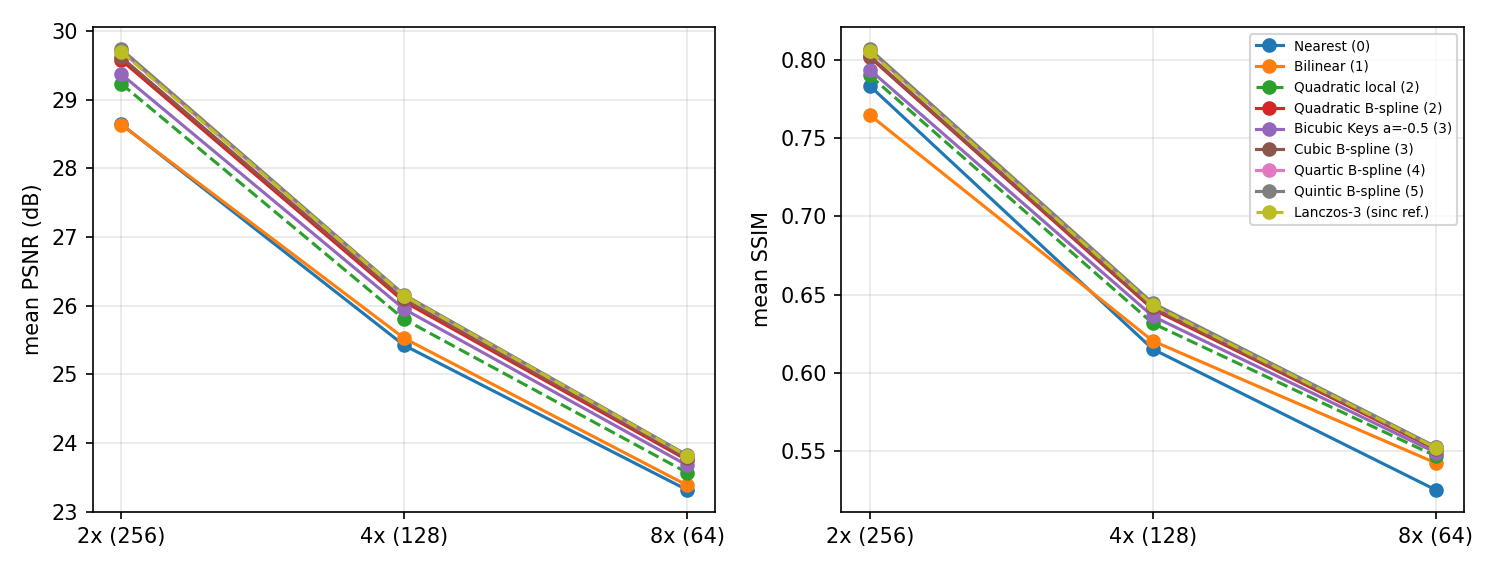

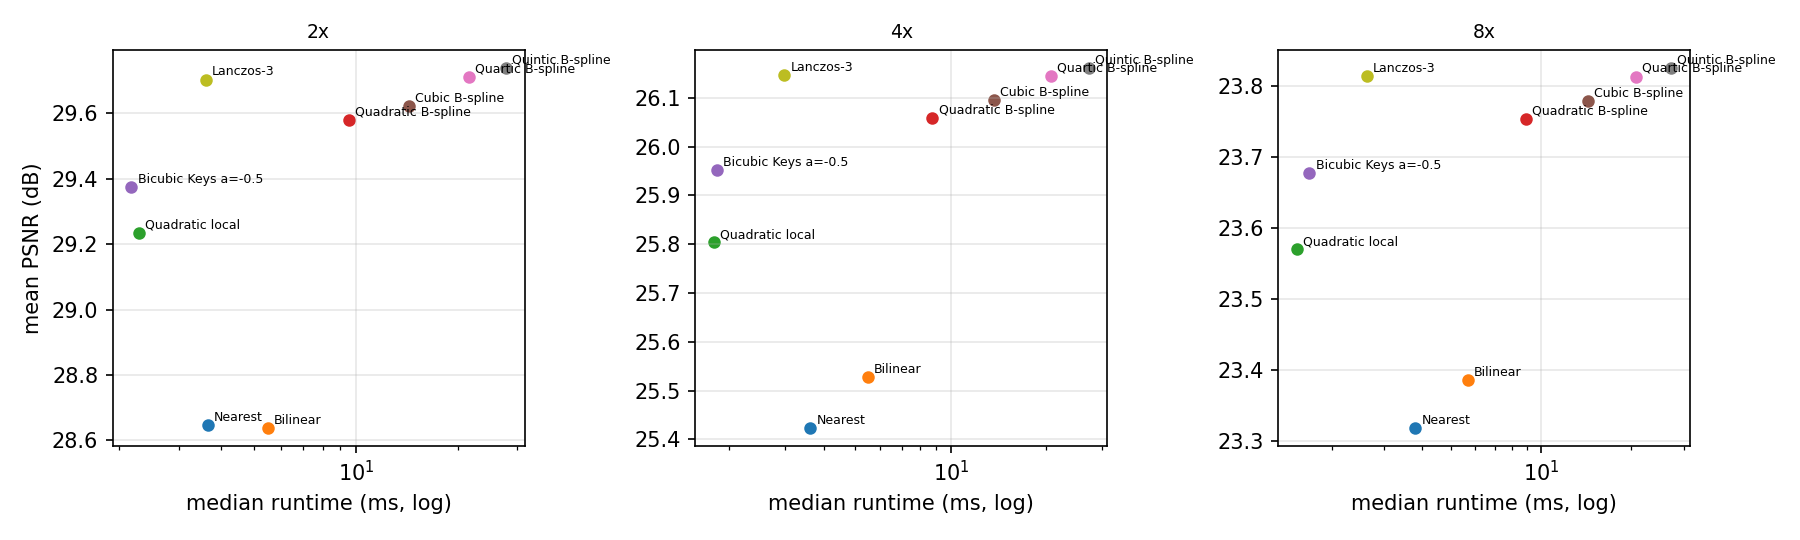

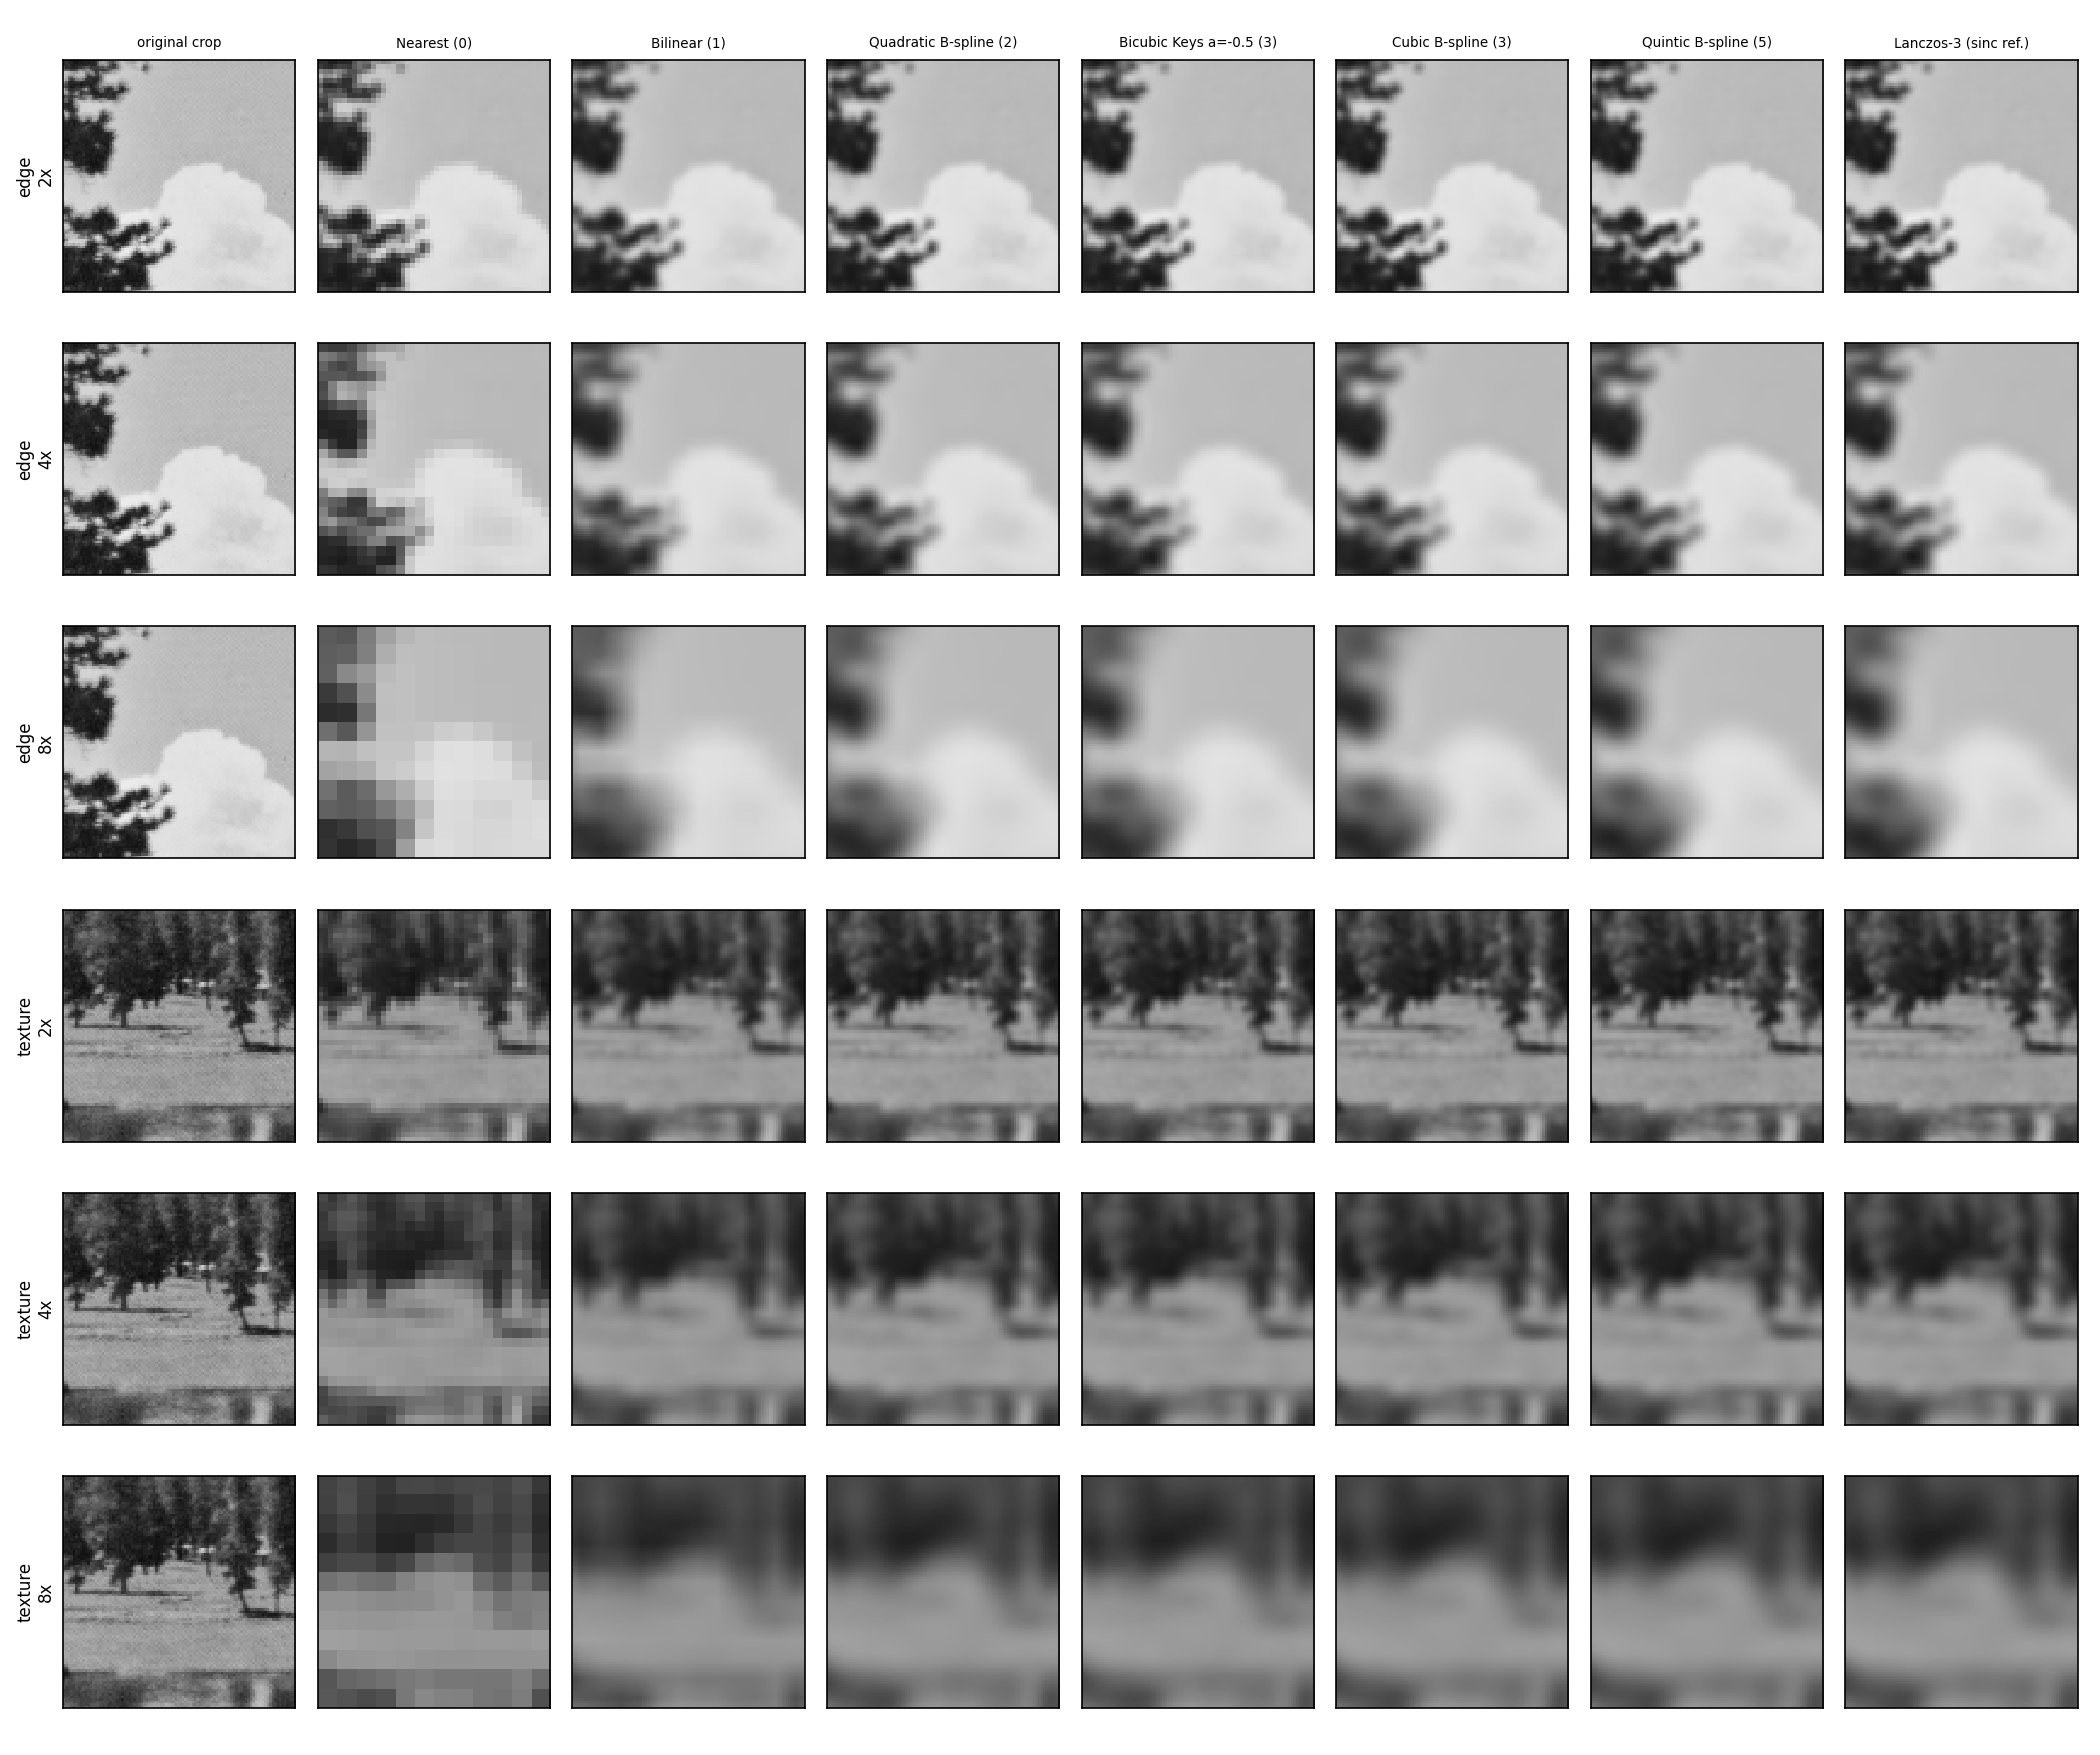

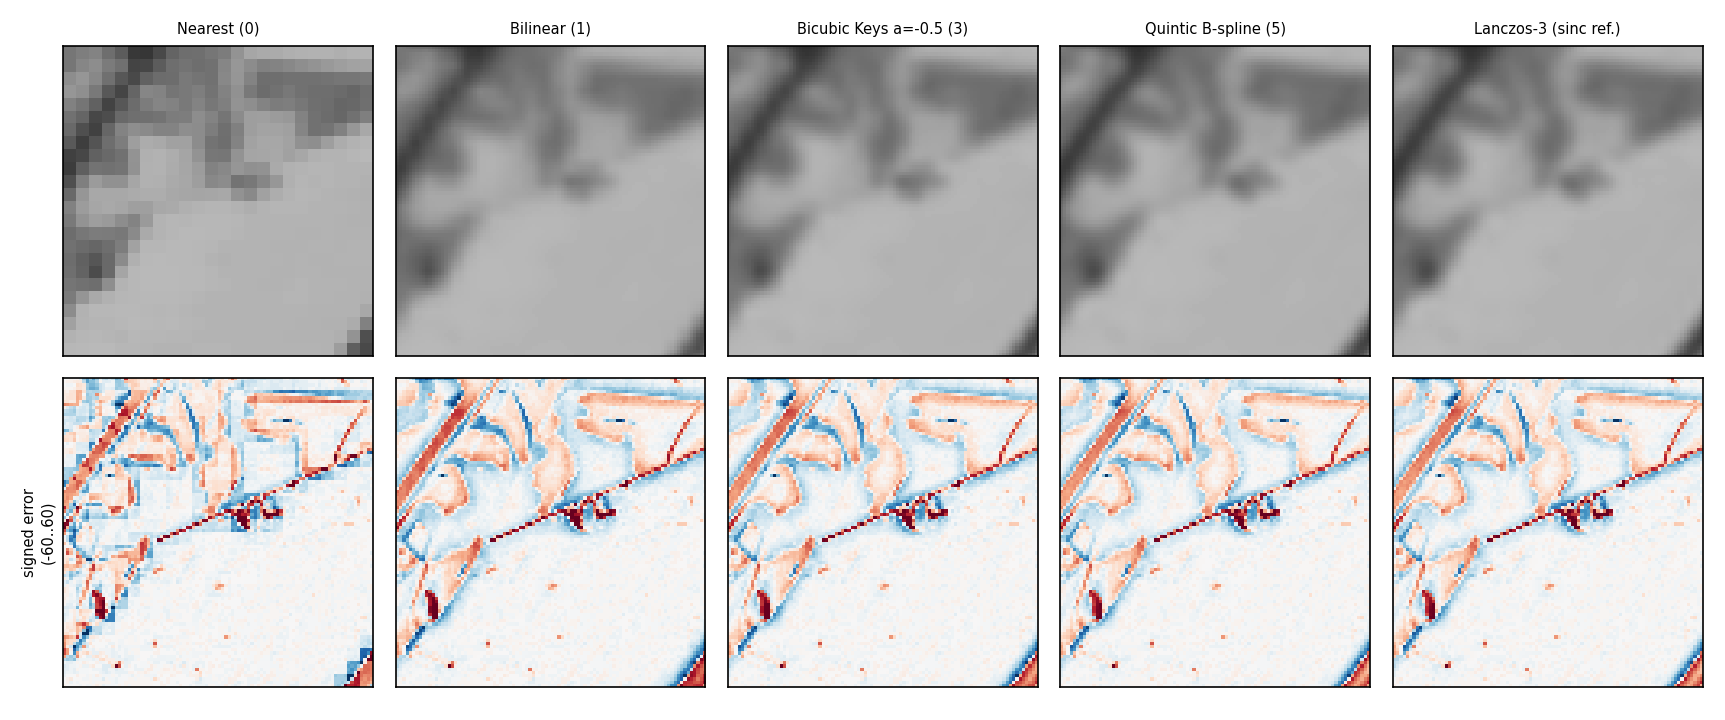

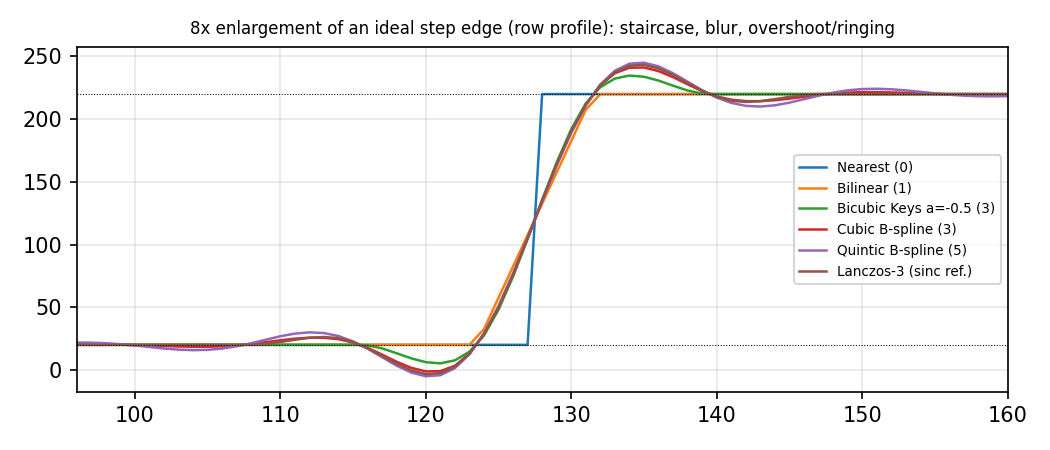

In [9]:
for f in ('fig1_originals_and_lr', 'fig4_quality_vs_scale', 'fig5_runtime_vs_psnr', 'fig6_error_maps', 'fig7_step_edge_profile'):
    pass
ra.fig_quality_vs_scale(q); ra.fig_runtime_vs_quality(q, rt); ra.fig_artifacts(images, lrs); ra.fig_sr_grids(images, lrs)
from IPython.display import Image, display
for f in ('fig4_quality_vs_scale', 'fig5_runtime_vs_psnr', 'fig2_sr_crops_4.2.06', 'fig6_error_maps', 'fig7_step_edge_profile'):
    display(Image(filename=f'figures/{f}.png', width=900))

## 8. Live demo cell — change image / scale / method

In [10]:
name, s, method = '4.2.03.tiff', 4, 'spline3'
lr = lrs[(name, s)]
t0 = time.perf_counter(); out = ops.upsample(lr, s, method, 'centered'); dt = (time.perf_counter()-t0)*1e3
sc = ev.score(images[name], out)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(lr, cmap='gray', vmin=0, vmax=255, interpolation='nearest'); ax[0].set_title(f'input {lr.shape}')
ax[1].imshow(np.clip(out, 0, 255), cmap='gray', vmin=0, vmax=255); ax[1].set_title(f'{method} {s}x  PSNR {sc["psnr"]:.2f}  SSIM {sc["ssim"]:.3f}  {dt:.1f} ms')
ax[2].imshow(images[name], cmap='gray', vmin=0, vmax=255); ax[2].set_title('original')
[a.axis('off') for a in ax]; plt.show()

/var/folders/b5/3_90vxz15tx4qhcy5r0gmn5c0000gn/T/ipykernel_39033/651869644.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  [a.axis('off') for a in ax]; plt.show()


## 9. Research extension (separate from the required study): consistent null-space SR
x̂ = B y + P F(y). F is a compact LR-space CNN (DirectLR w96 d12 + bicubic skip), and B, P come from the exact P1 operator. Weights are listed in `extension/model_manifest.json` (SHA-256 checked). Roles were selected on validation images only; see report §6–7.

In [11]:
import json, subprocess
roles = pd.read_csv('extension/results/role_table.csv')
roles[roles.scope == 'overall'][['scale', 'role', 'method_id', 'val_psnr', 'val_ssim', 'latency_median_ms', 'x_torch_bicubic', 'assignment_psnr', 'assignment_ssim', 'urban100c_psnr', 'urban100c_ssim']]

,scale,role,method_id,val_psnr,val_ssim,latency_median_ms,x_torch_bicubic,assignment_psnr,assignment_ssim,urban100c_psnr,urban100c_ssim
0,2,Highest PSNR,finetuned:swinirP1_x2_bsd_s20260915_psnr+proj,34.106,0.918,3934.104,3184.00,33.029,0.886,30.901,0.923
1,2,Highest SSIM,finetuned:swinirP1_x2_bsd_s20260915_ssim+proj,34.020,0.918,3934.104,3184.00,33.025,0.886,30.922,0.923
2,2,Lowest latency,classical:torch_bicubic,29.320,0.834,1.236,1.00,29.586,0.801,23.630,0.755
3,2,Best trade-off (promoted),classical:torch_bicubic+proj,31.342,0.896,2.116,1.71,31.370,0.869,25.641,0.839
8,4,Highest PSNR,finetuned:swinirP1_x4_bsd_s20260915_psnr+proj,29.221,0.776,727.727,680.94,28.788,0.737,24.260,0.748
9,4,Highest SSIM,finetuned:swinirP1_x4_bsd_s20260915_ssim+proj,29.166,0.777,727.727,680.94,28.776,0.737,24.280,0.748
10,4,Lowest latency,classical:torch_bicubic,25.244,0.643,1.069,1.00,26.079,0.640,20.217,0.528
11,4,Best trade-off (promoted),classical:torch_bicubic+proj,26.872,0.723,1.638,1.53,27.602,0.709,21.542,0.614
16,8,Highest PSNR,finetuned:swinirP1_x8_bsd_s20260915_psnr+proj,25.142,0.609,386.964,373.05,25.912,0.611,20.635,0.544
17,8,Highest SSIM,finetuned:swinirP1_x8_bsd_s20260915_psnr,25.105,0.609,230.942,222.64,25.866,0.612,20.607,0.544


In [12]:
r = subprocess.run([sys.executable, 'code/run_extension_demo.py'], capture_output=True, text=True)
print(r.stdout[-3000:], r.stderr[-2000:])
assert r.returncode == 0

                                                      psnr    ssim  ms_single_run  abs_diff_db  lr_residual_rms
scale role     method_id                                                                                       
2     psnr     ours:fs_x2_bsd_s20260915_psnr+proj  32.6415  0.8809        65.0752       0.0001           0.0000
      ssim     ours:fs_x2_bsd_s20260915_ssim+proj  32.6501  0.8809        44.4396       0.0000           0.0000
4     psnr     ours:fs_x4_bsd_s20260915_psnr+proj  28.3878  0.7285        13.4201       0.0002           0.0000
      ssim     ours:fs_x4_bsd_s20260915_ssim+proj  28.4062  0.7287        13.6682       0.0001           0.0000
8     promoted ours:fs_x8_bsd_s7_psnr              25.7064  0.6028         9.0586       0.0002           0.3262
      psnr     ours:fs_x8_bsd_s7_psnr+proj         25.7239  0.6028        10.6011       0.0002           0.0025
      ssim     ours:fs_x8_bsd_s7_ssim+proj         25.7222  0.6031         9.9303       0.0002          

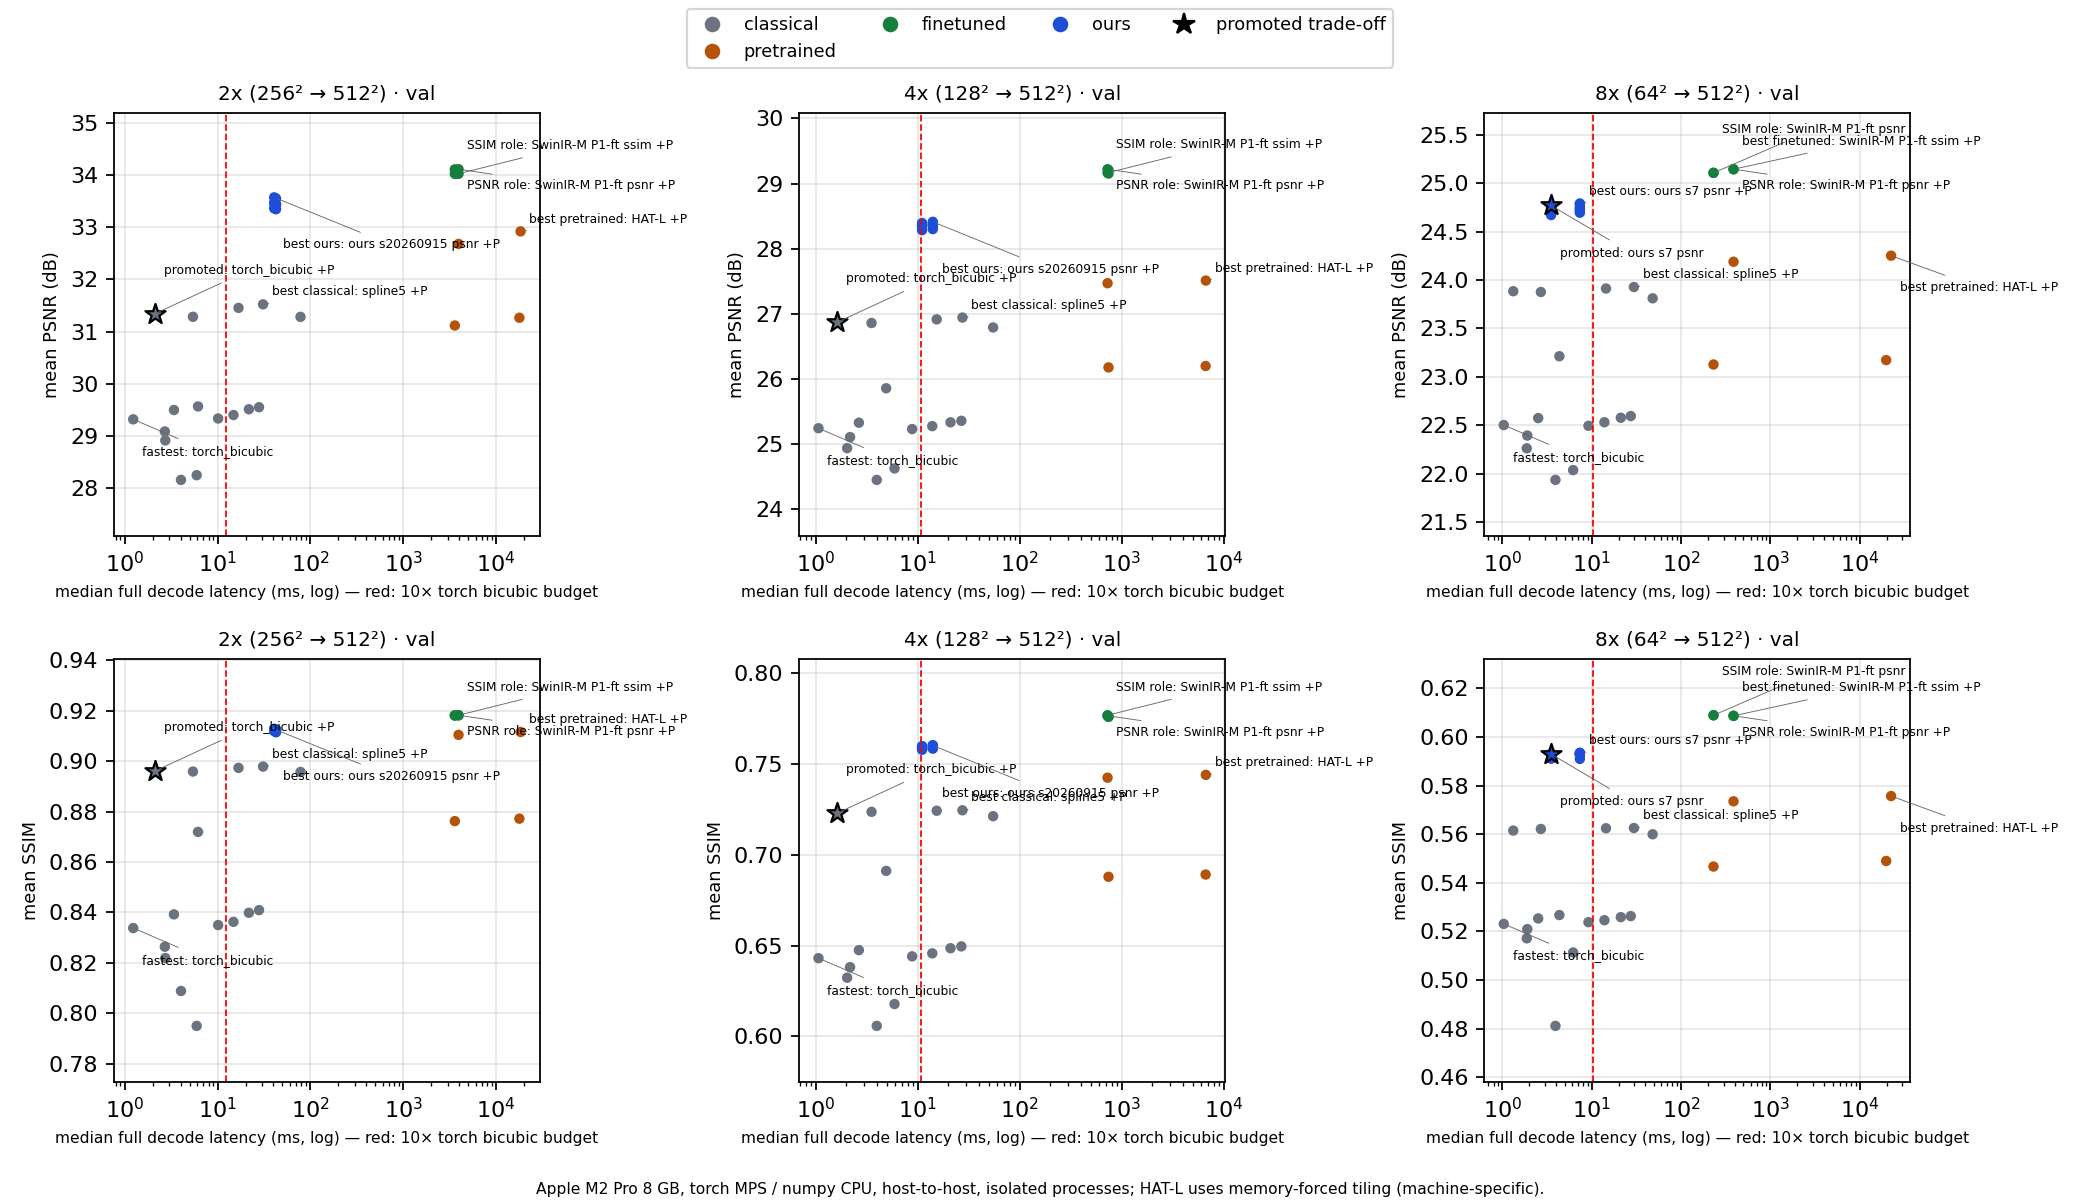

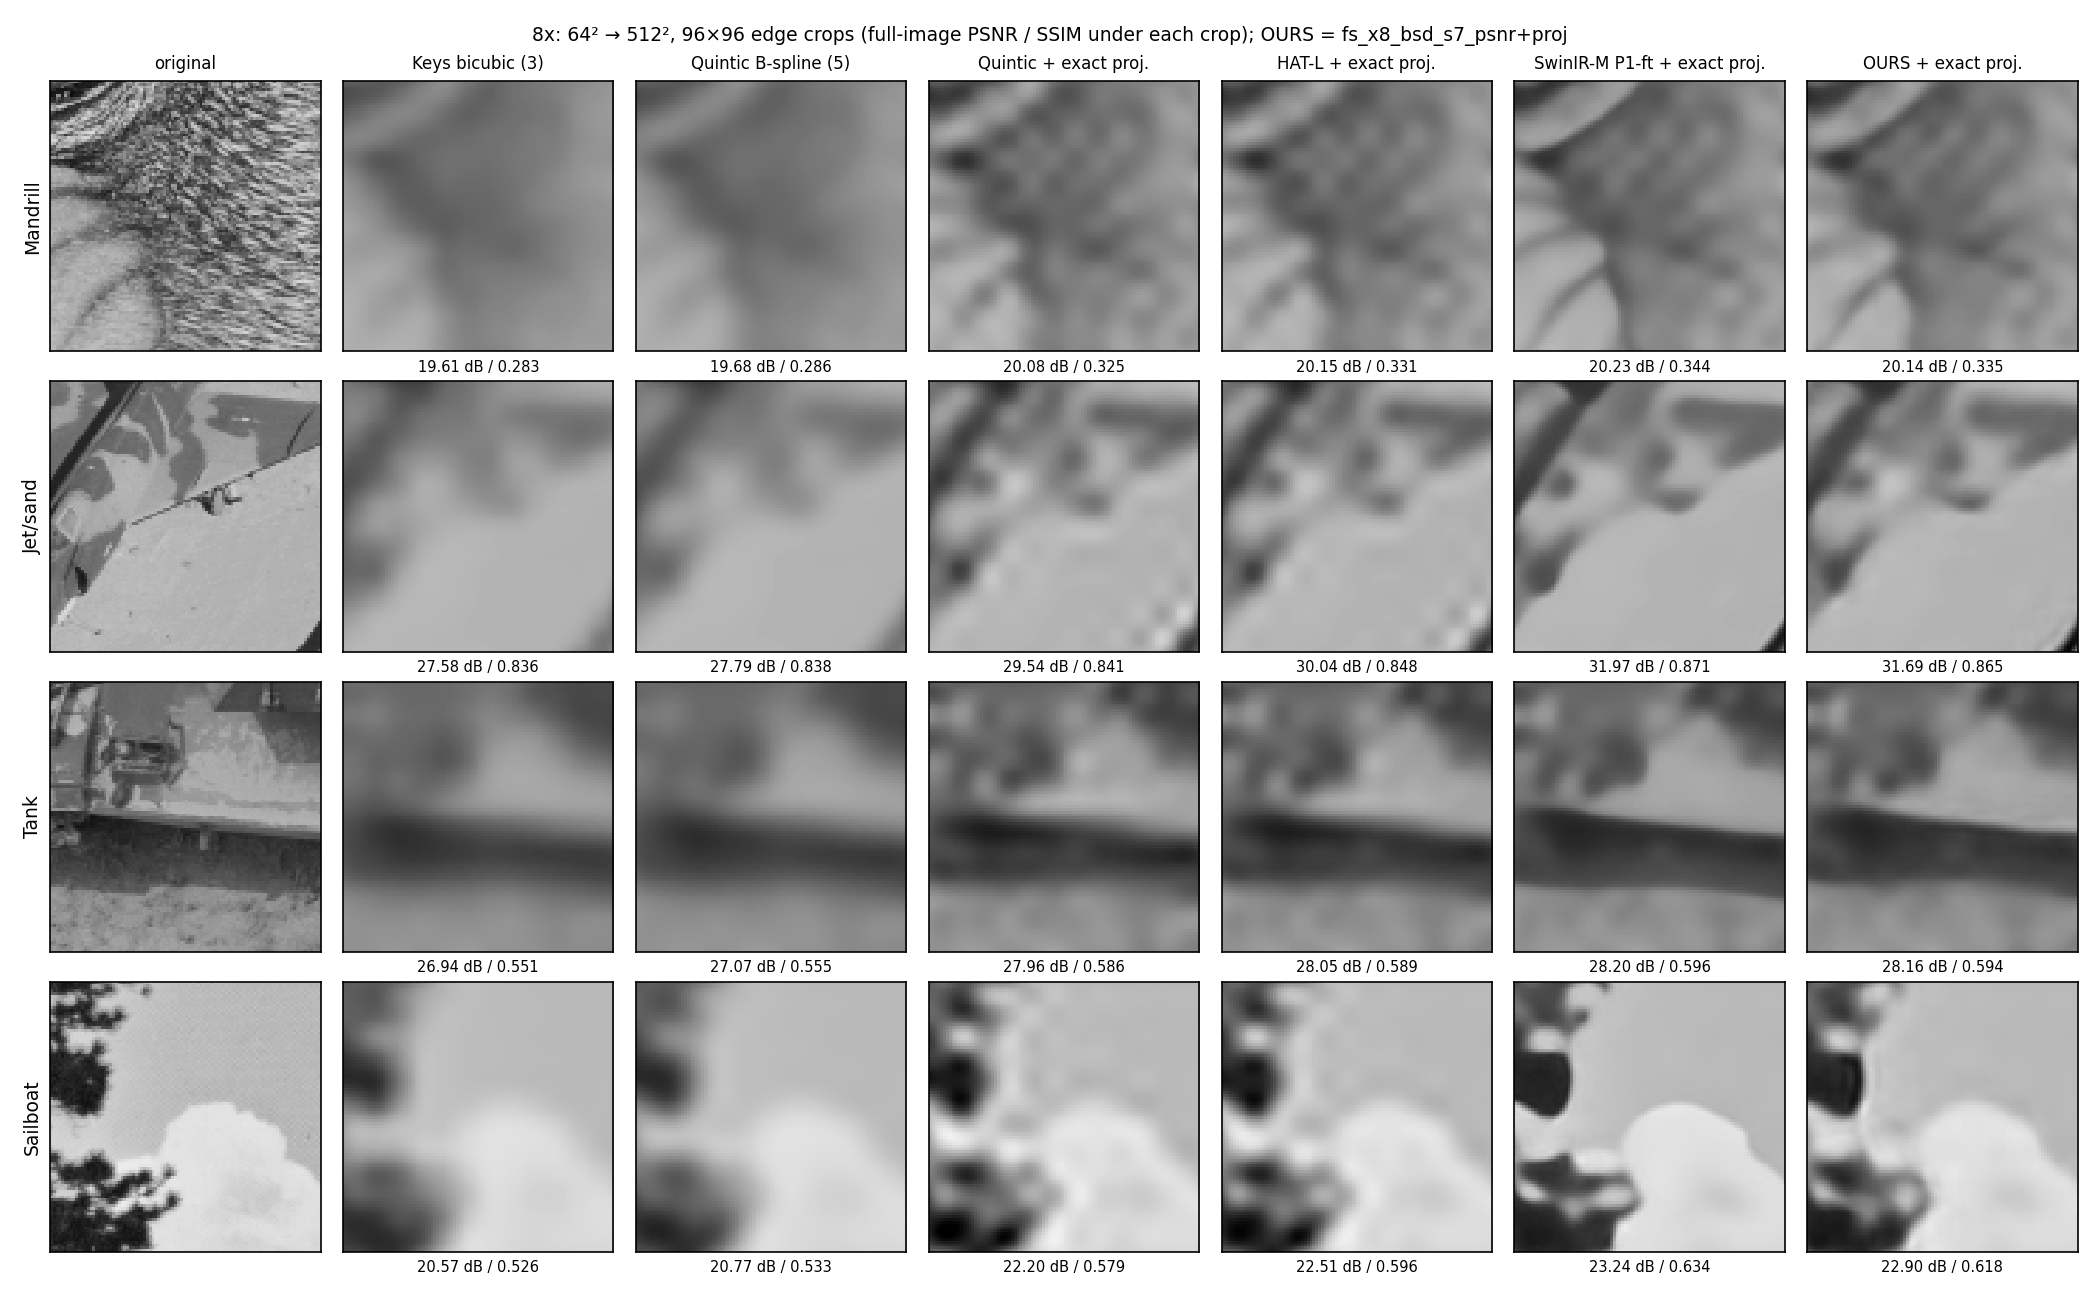

In [13]:
from IPython.display import Image, display
display(Image(filename='extension/results/fig_tradeoff_val.png', width=950))
display(Image(filename='extension/figures/ext_crops_x8.png', width=950))

### Live extension cell — change image / scale / role

In [14]:
import sr_extension as X
name, s, role = '4.2.06.tiff', 8, 'psnr'
net, entry = X.load_model(s, role)
lr = lrs[(name, s)]
X.super_resolve(lr, s, net)
t0 = time.perf_counter(); out = X.super_resolve(lr, s, net, entry['projection']); dt = (time.perf_counter() - t0) * 1e3
base = ops.upsample(lr, s, 'spline5', 'centered')
fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
for a, (t, im) in zip(ax, (('quintic B-spline %.2f dB' % ev.score(images[name], base)['psnr'], base), (f"{entry['method_id']}  {ev.score(images[name], out)['psnr']:.2f} dB / {ev.score(images[name], out)['ssim']:.3f}  {dt:.1f} ms", out), ('original', images[name]))):
    a.imshow(np.clip(im, 0, 255), cmap='gray', vmin=0, vmax=255); a.set_title(t, fontsize=8); a.axis('off')
plt.show(); print('LR residual RMS (grey levels):', X.lr_residual(out, lr, s))

LR residual RMS (grey levels): 0.009824693295809851


/var/folders/b5/3_90vxz15tx4qhcy5r0gmn5c0000gn/T/ipykernel_39033/1535583856.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show(); print('LR residual RMS (grey levels):', X.lr_residual(out, lr, s))
